<a href="https://colab.research.google.com/github/victormaciel13/alertabairro-visao/blob/main/alertabairro_visao_treino_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AlertaBairro · Visão Computacional · Treino v1 (baseline)

Primeiro treino do detector de alagamento com YOLO11.

**Antes de rodar:**
1. `Ambiente de execução > Alterar o tipo de ambiente de execução > GPU T4`
2. Na barra lateral, ícone da chave (🔑 Secrets): crie `ROBOFLOW_API_KEY` com a sua chave do Roboflow e ative o acesso do notebook
3. Preencha `WORKSPACE`, `PROJECT` e `VERSION` na célula de configuração
4. `Ambiente de execução > Executar tudo`

Os resultados vão para o seu Google Drive, então nada se perde se o Colab desconectar.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
!pip install -q ultralytics roboflow

## 1. Configuração

In [ ]:
from google.colab import userdata, drive

# Chave fora do código (mesma regra que o Gitleaks vai cobrar no DevOps)
ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")

# Copie estes 3 valores do snippet "Download Dataset > YOLOv11" do Roboflow
WORKSPACE = "victors-workspace-1li59"
PROJECT   = "water-logging-go16i-avmp0"
VERSION   = 1
EPOCHS    = 80

# Parâmetros do treino
MODELO_BASE = "yolo11s.pt"   # troque por yolo11s.pt se o resultado ficar fraco
EPOCHS      = 100
IMGSZ       = 640
BATCH       = 16
RUN_NAME    = "v2_yolo11s"

drive.mount("/content/drive")
PROJECT_DIR = "/content/drive/MyDrive/alertabairro/runs"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Download do dataset

In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
dataset = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION).download("yolov11")
DATA_DIR = dataset.location
print("Dataset em:", DATA_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to water-logging-1 in yolov11:: 100%|██████████| 982/982 [00:00<00:00, 1760.50it/s]

Dataset em: /content/water-logging-1


In [ ]:
# Corrige os caminhos do data.yaml (o export do Roboflow usa caminhos relativos que às vezes quebram)
import yaml, os

yaml_path = os.path.join(DATA_DIR, "data.yaml")
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg["train"] = os.path.join(DATA_DIR, "train", "images")
cfg["val"]   = os.path.join(DATA_DIR, "valid", "images")
test_dir = os.path.join(DATA_DIR, "test", "images")
if os.path.isdir(test_dir):
    cfg["test"] = test_dir
else:
    cfg.pop("test", None)

with open(yaml_path, "w") as f:
    yaml.safe_dump(cfg, f)

print("Classes:", cfg["names"])
for split in ["train", "valid", "test"]:
    d = os.path.join(DATA_DIR, split, "images")
    if os.path.isdir(d):
        print(f"{split:>5}: {len(os.listdir(d))} imagens")

Classes: ['water_logging']
train: 435 imagens
valid: 39 imagens
 test: 15 imagens


**Confira a saída acima antes de seguir.** Se as classes não tiverem relação com água na via ou se o treino tiver menos de ~300 imagens, troque o dataset agora: é mais rápido que descobrir isso depois de 50 épocas.

## 3. Treino

In [ ]:
from ultralytics import YOLO

model = YOLO(MODELO_BASE)
model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=30,        # para cedo se não melhorar por 20 épocas
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=42,            # reprodutibilidade para o relatório
    plots=True,
)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/water-logging-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v2_yolo11s, nbs=64, nms=None, opset=None, optimize=Fal

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a388c3769e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

> Se o Colab cair no meio do treino, rode só a célula de configuração e depois esta:
> ```python
> YOLO(f"{PROJECT_DIR}/{RUN_NAME}/weights/last.pt").train(resume=True)
> ```

## 4. Avaliação (números do relatório)

In [ ]:
RUN_DIR = f"{PROJECT_DIR}/{RUN_NAME}"
best = YOLO(f"{RUN_DIR}/weights/best.pt")
m = best.val(data=yaml_path, split="val")

print(f"mAP50     : {m.box.map50:.3f}")
print(f"mAP50-95  : {m.box.map:.3f}")
print(f"Precisão  : {m.box.mp:.3f}")
print(f"Recall    : {m.box.mr:.3f}")
print()
for i, nome in best.names.items():
    if i < len(m.box.ap50):
        print(f"  {nome:<25} AP50 = {m.box.ap50[i]:.3f}")

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2214.6±554.6 MB/s, size: 55.3 KB)
val: Scanning /content/water-logging-1/valid/labels.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 9.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.4it/s 1.3s
                   all         39         86      0.427      0.291      0.275      0.133
Speed: 2.4ms preprocess, 8.7ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /content/runs/detect/val
mAP50     : 0.275
mAP50-95  : 0.133
Precisão  : 0.427
Recall    : 0.291

  water_logging             AP50 = 0.275


results.png


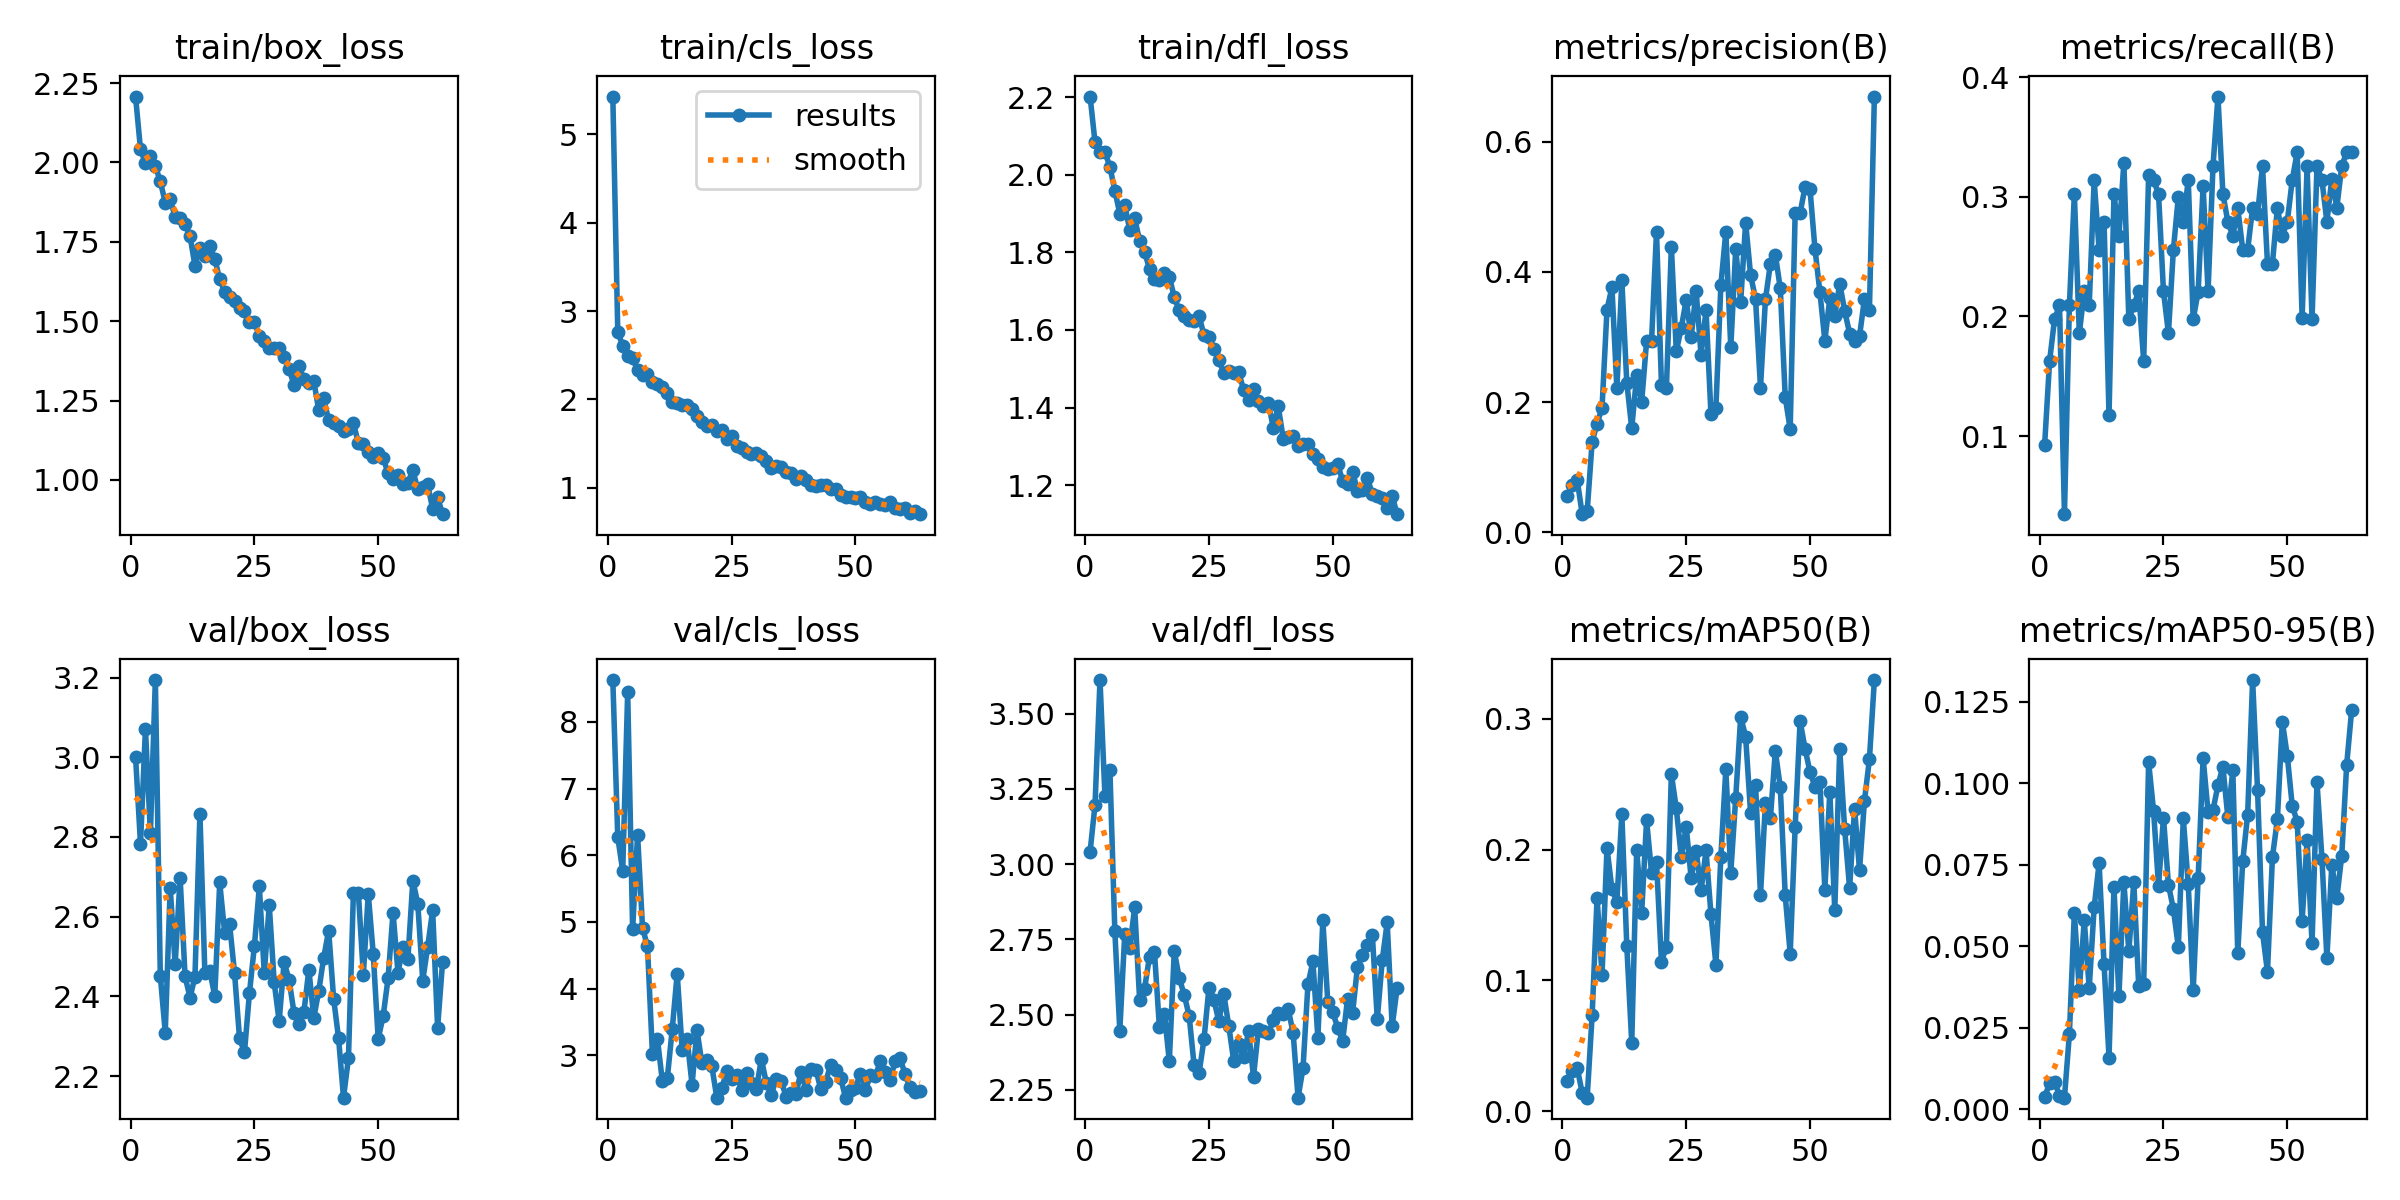

confusion_matrix.png


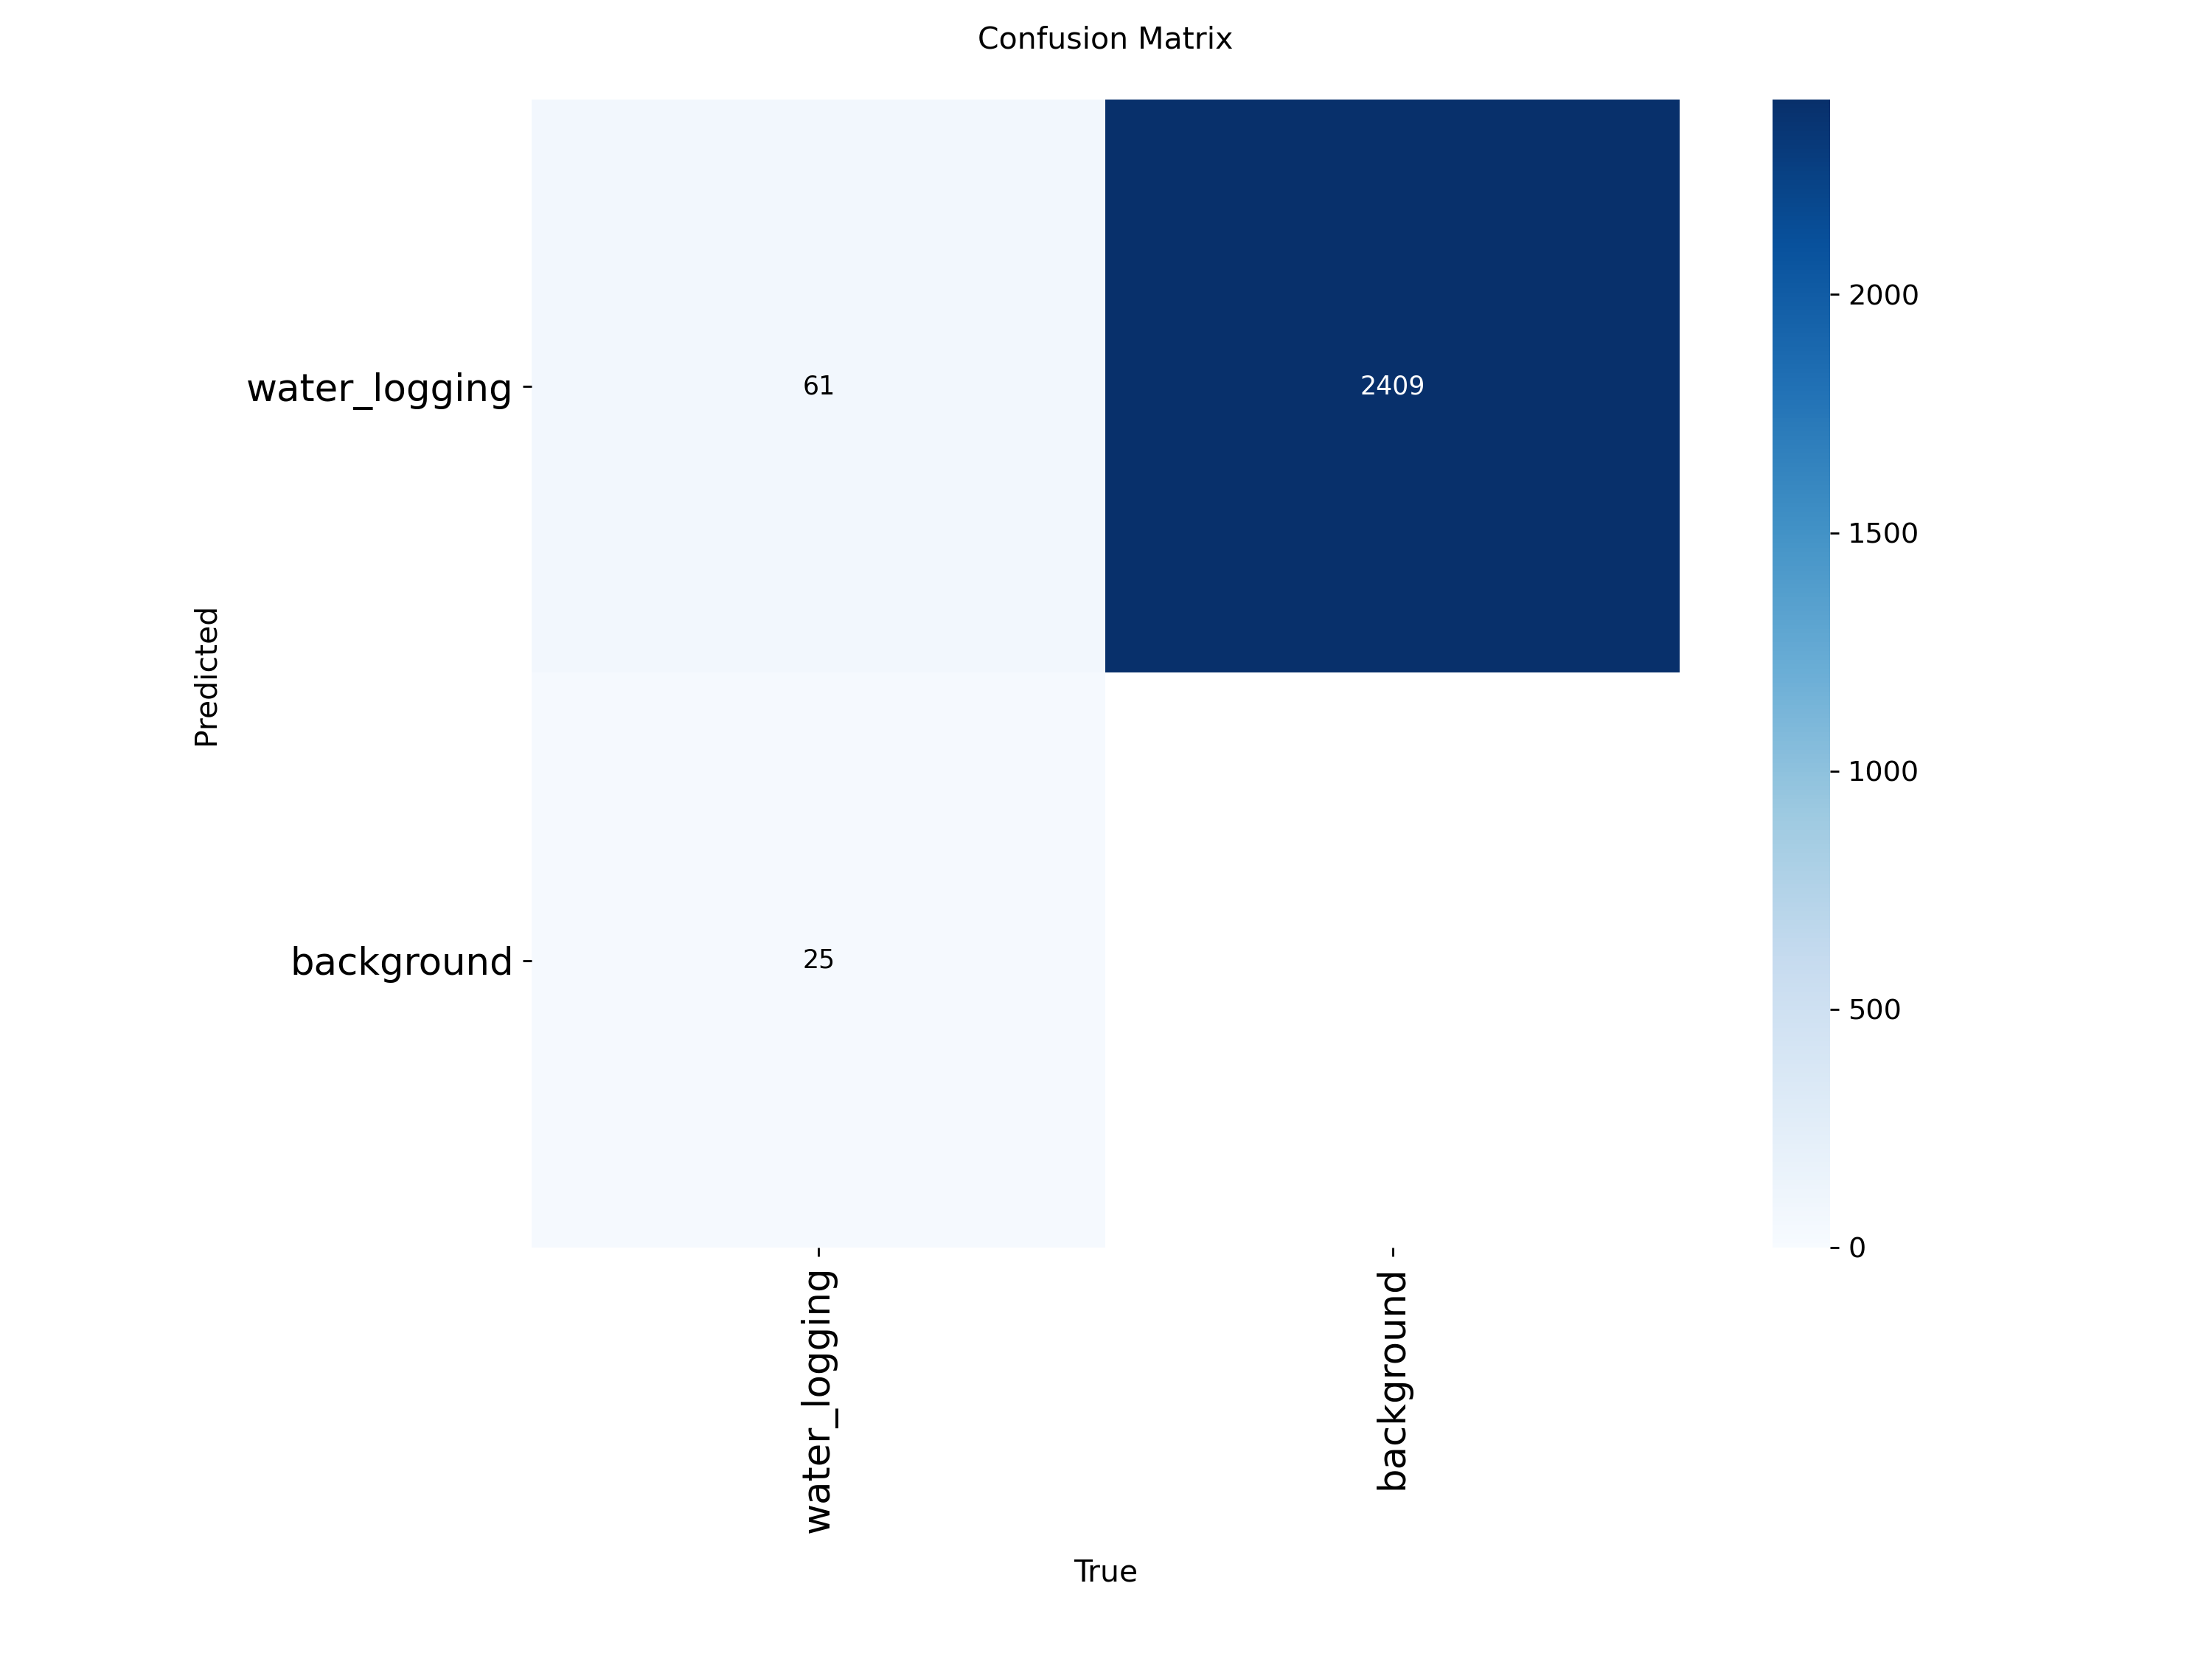

In [ ]:
from IPython.display import Image, display

for arq in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    caminho = f"{RUN_DIR}/{arq}"
    if os.path.exists(caminho):
        print(arq)
        display(Image(filename=caminho, width=800))

## 5. Exemplos de predição (prints para o PDF)


0: 640x640 4 water_loggings, 5.3ms
1: 640x640 2 water_loggings, 5.3ms
2: 640x640 (no detections), 5.3ms
3: 640x640 3 water_loggings, 5.3ms
4: 640x640 1 water_logging, 5.3ms
5: 640x640 3 water_loggings, 5.3ms
Speed: 0.9ms preprocess, 5.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/alertabairro/runs/v1_baseline/exemplos


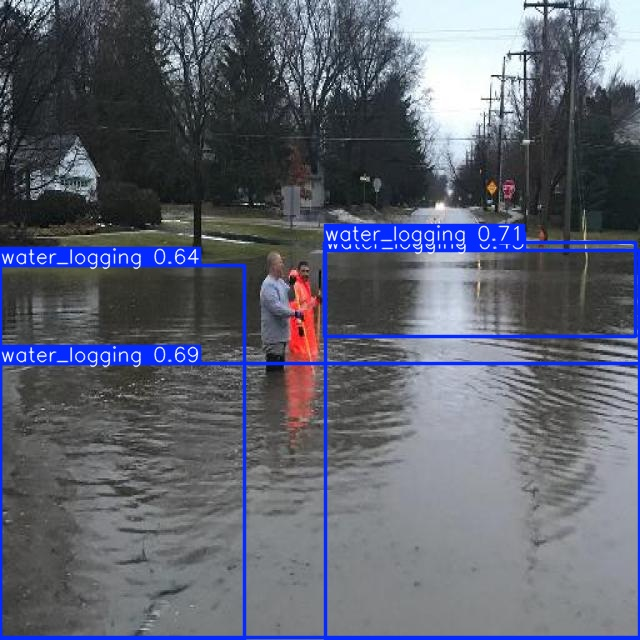

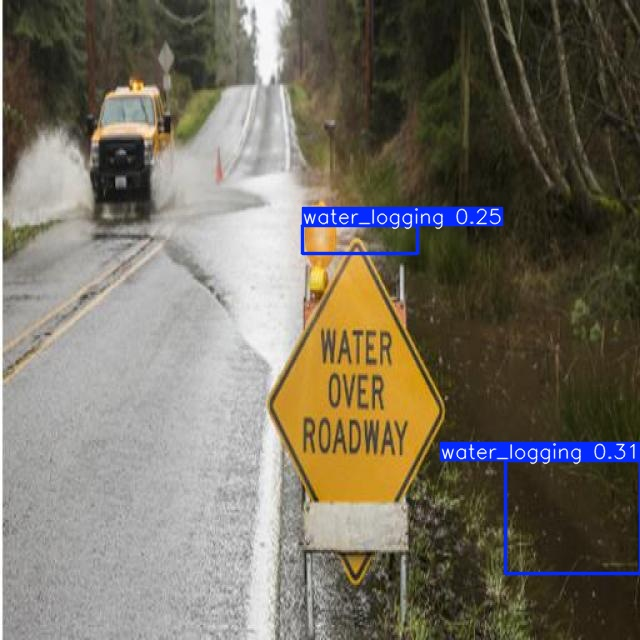

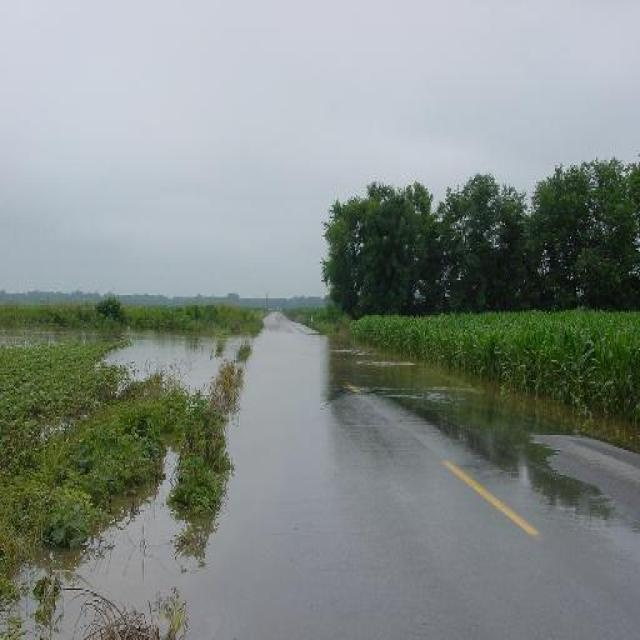

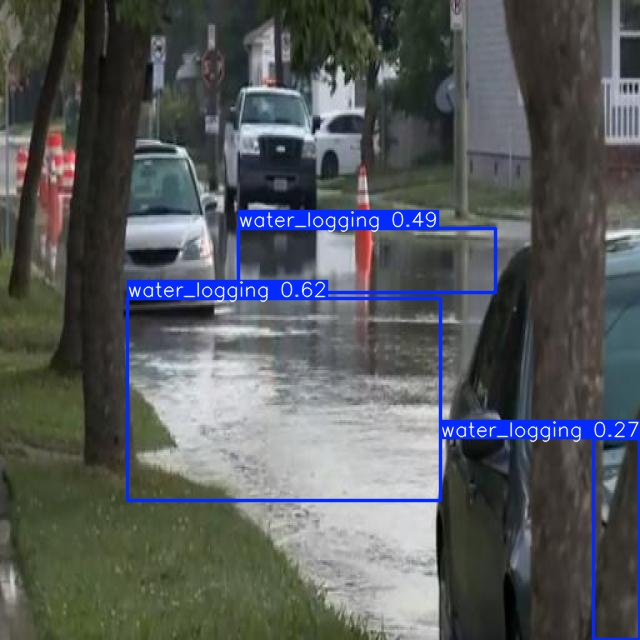

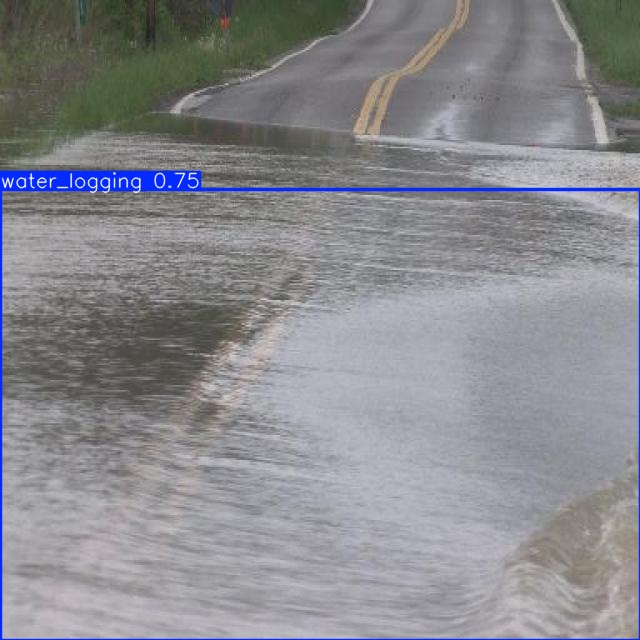

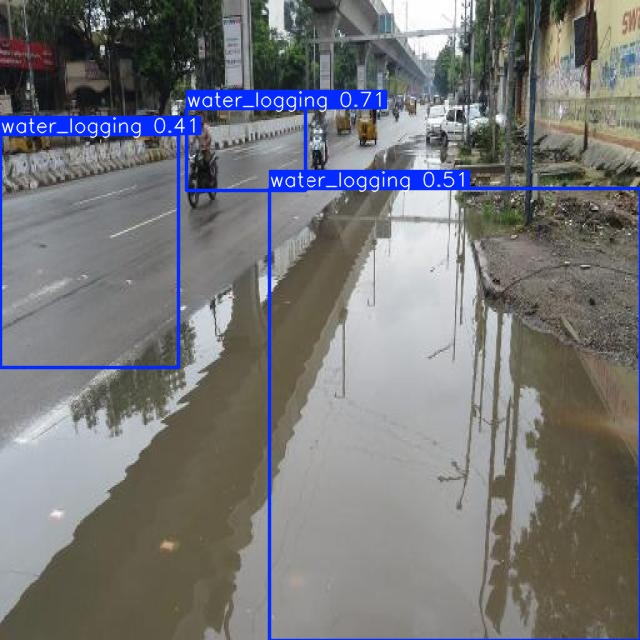

In [ ]:
import glob

amostras = sorted(glob.glob(os.path.join(DATA_DIR, "valid", "images", "*")))[:6]
best.predict(amostras, conf=0.25, save=True, project=RUN_DIR, name="exemplos", exist_ok=True)

for p in sorted(glob.glob(f"{RUN_DIR}/exemplos/*"))[:6]:
    display(Image(filename=p, width=500))

## 6. Salvar o modelo para a API

In [ ]:
import shutil

destino = "/content/drive/MyDrive/alertabairro/modelos/alertabairro_v1.pt"
os.makedirs(os.path.dirname(destino), exist_ok=True)
shutil.copy(f"{RUN_DIR}/weights/best.pt", destino)
print("Modelo salvo em:", destino)

Modelo salvo em: /content/drive/MyDrive/alertabairro/modelos/alertabairro_v1.pt


In [ ]:
import cv2, time
from ultralytics import YOLO

VIDEO_IN  = "/content/drive/MyDrive/alertabairro/videos/rua_alagada.mp4"
VIDEO_OUT = "/content/drive/MyDrive/alertabairro/videos/rua_alagada_detectado.mp4"

model = YOLO("/content/drive/MyDrive/alertabairro/modelos/alertabairro_v1.pt")
cap = cv2.VideoCapture(VIDEO_IN)
fps_in = cap.get(cv2.CAP_PROP_FPS) or 30
w, h = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter(VIDEO_OUT, cv2.VideoWriter_fourcc(*"mp4v"), fps_in, (w, h))

frames, com_agua, t0 = 0, 0, time.time()
while True:
    ok, frame = cap.read()
    if not ok:
        break
    r = model.predict(frame, conf=0.5, verbose=False)[0]
    img = r.plot()
    alagado = len(r.boxes) > 0
    com_agua += alagado
    frames += 1
    fps = frames / (time.time() - t0)
    texto = "ALAGAMENTO DETECTADO" if alagado else "Sem alagamento"
    cor = (0, 0, 255) if alagado else (0, 200, 0)
    cv2.putText(img, f"{texto} | {fps:.0f} FPS", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1, cor, 2)
    out.write(img)

cap.release(); out.release()
print(f"{frames} frames | {frames/(time.time()-t0):.1f} FPS médio | "
      f"alagamento em {com_agua/frames:.0%} dos frames")
print("Vídeo salvo em:", VIDEO_OUT)

1772 frames | 18.2 FPS médio | alagamento em 92% dos frames
Vídeo salvo em: /content/drive/MyDrive/alertabairro/videos/rua_alagada_detectado.mp4


In [ ]:
modelos = {
    "v1 (yolo11n)": f"{PROJECT_DIR}/v1_baseline/weights/best.pt",
    "v2 (yolo11s)": f"{PROJECT_DIR}/v2_yolo11s/weights/best.pt",
}
for nome, caminho in modelos.items():
    mdl = YOLO(caminho)
    m = mdl.val(data=yaml_path, split="val", verbose=False)
    linha = (f"{nome}: mAP50={m.box.map50:.3f} | mAP50-95={m.box.map:.3f} "
             f"| P={m.box.mp:.3f} | R={m.box.mr:.3f}")
    for split in ["valid", "test"]:
        imgs = sorted(glob.glob(os.path.join(DATA_DIR, split, "images", "*")))
        res = mdl.predict(imgs, conf=0.5, verbose=False)
        ok = sum(len(r.boxes) > 0 for r in res)
        linha += f" | {split}: {ok}/{len(imgs)}"
    print(linha)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1649.3±415.8 MB/s, size: 55.3 KB)
val: Scanning /content/water-logging-1/valid/labels.cache... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 10.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.0it/s 1.5s
                   all         39         86      0.427      0.291      0.275      0.133
Speed: 4.9ms preprocess, 10.2ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val-3
v1 (yolo11n): mAP50=0.275 | mAP50-95=0.133 | P=0.427 | R=0.291 | valid: 22/39 | test: 8/15
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast im